<a href="https://colab.research.google.com/github/iindrisw/PROJEK-MACHINE-LEARNING-1/blob/main/03_varian_2_FIX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Varian Perlakuan Data: Deteksi & Penanganan Outlier (IQR) + Penskalaan (Seluruh Fitur)

=== ANALISIS VARIABEL TARGET (G3) ===


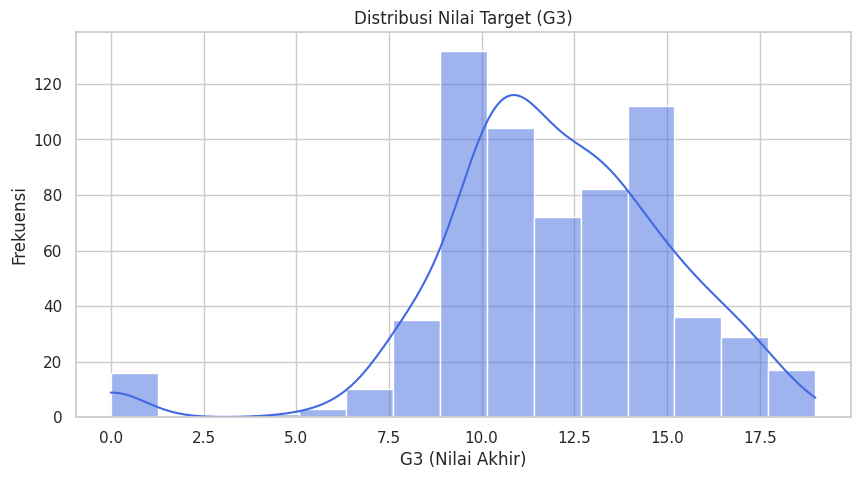

Skewness dari G3: -0.9129
Catatan: Distribusi target relatif simetris/normal.

Jumlah nilai unik pada G3: 17
Daftar nilai unik G3: [np.int64(0), np.int64(1), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]
Keterbatasan: Target merupakan skor bulat (diskrit/ordinal). Residu model regresi kemungkinan akan membentuk pola bertingkat.

Jumlah nilai 0 pada target G3: 15 siswa.
Catatan: Nilai 0 mungkin merepresentasikan siswa yang drop-out atau tidak mengikuti ujian akhir.

Korelasi Fitur Numerik dengan Target (G3):
G3            1.000000
G2            0.918548
G1            0.826387
studytime     0.249789
Medu          0.240151
Fedu          0.211800
famrel        0.063361
goout        -0.087641
absences     -0.091379
health       -0.098851
age          -0.106505
freetime     -0.122705
traveltime   -0.127173
Walc         -0.176619
Dalc  

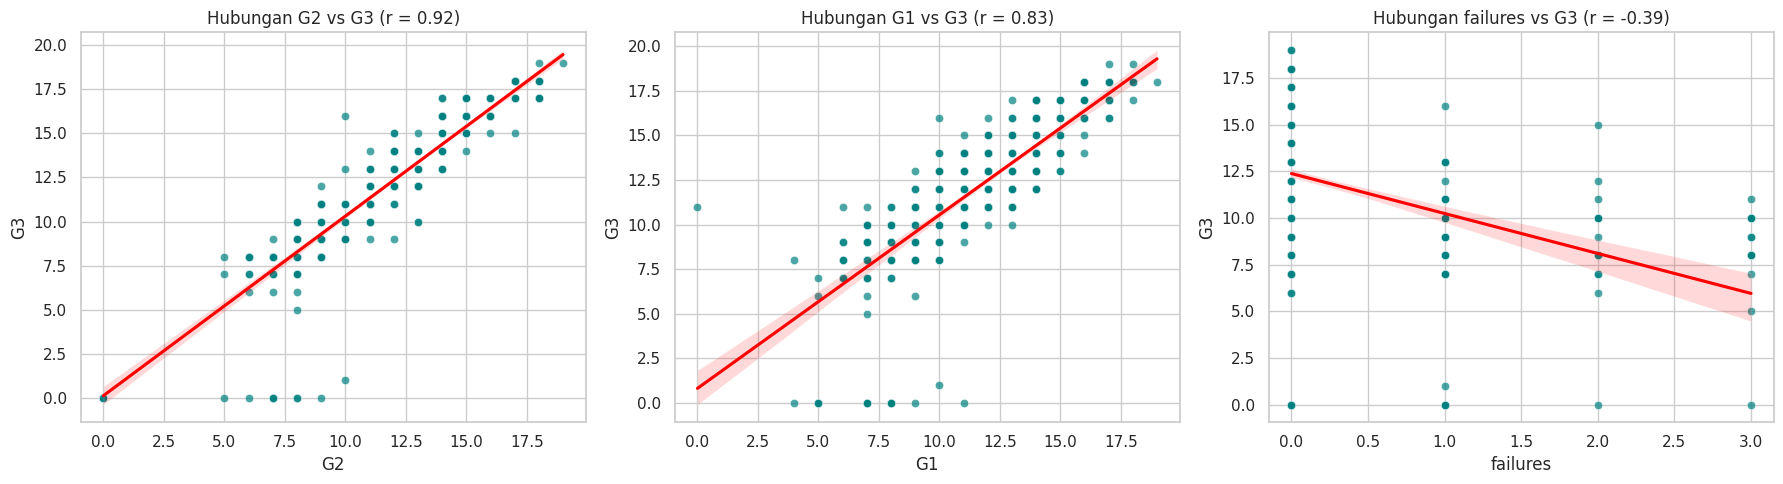


=== PERKIRAAN / HIPOTESIS SEBELUM PEMODELAN ===
1. Fitur 'G2' dan 'G1' diperkirakan paling berpengaruh karena nilai akademis sebelumnya mencerminkan konsistensi performa siswa.
2. Fitur 'failures' diperkirakan berpengaruh negatif kuat karena riwayat kegagalan kelas sebelumnya menurunkan motivasi dan fondasi akademis.
3. Fitur 'absences' diperkirakan berpengaruh negatif karena ketidakhadiran mengurangi waktu belajar efektif.

=== HASIL VARIAN PERLAKUAN DATA (SELURUH FITUR + IQR + SCALING) ===
MAE  : 0.8771
RMSE : 1.3371
R2   : 0.8167


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set gaya visualisasi
sns.set_theme(style="whitegrid")

# 1. Load data bersih dari path yang benar
df_all = pd.read_csv('/content/student_por_clean.csv')

# ==========================================
# ANALISIS TARGET (G3) SESUAI KETENTUAN
# ==========================================
print("=== ANALISIS VARIABEL TARGET (G3) ===")

# A. Bentuk Sebaran (Histogram)
plt.figure(figsize=(10, 5))
sns.histplot(df_all['G3'], kde=True, bins=15, color='royalblue')
plt.title('Distribusi Nilai Target (G3)')
plt.xlabel('G3 (Nilai Akhir)')
plt.ylabel('Frekuensi')
plt.show()

# Evaluasi Kemencengan (Skewness)
skewness = df_all['G3'].skew()
print(f"Skewness dari G3: {skewness:.4f}")
if abs(skewness) > 1:
    print("Catatan: Target menceng kuat. Regresi linear mungkin kurang akurat pada bagian ekor sebaran.")
else:
    print("Catatan: Distribusi target relatif simetris/normal.")

# B. Pemeriksaan Karakter Kontinu & Nilai Unik
unik_g3 = sorted(df_all['G3'].unique())
print(f"\nJumlah nilai unik pada G3: {len(unik_g3)}")
print(f"Daftar nilai unik G3: {unik_g3}")
print("Keterbatasan: Target merupakan skor bulat (diskrit/ordinal). Residu model regresi kemungkinan akan membentuk pola bertingkat.")

# C. Nilai Mustahil (Nilai 0 pada G3)
jumlah_nol = (df_all['G3'] == 0).sum()
print(f"\nJumlah nilai 0 pada target G3: {jumlah_nol} siswa.")
print("Catatan: Nilai 0 mungkin merepresentasikan siswa yang drop-out atau tidak mengikuti ujian akhir.")

# D. Hubungan dengan Calon Fitur (Korelasi & Scatter Plot)
fitur_numerik_all = df_all.select_dtypes(include=[np.number]).columns.tolist()
korelasi_g3 = df_all[fitur_numerik_all].corr()['G3'].sort_values(ascending=False)
print("\nKorelasi Fitur Numerik dengan Target (G3):")
print(korelasi_g3)

# Peringatan Kebocoran Data
for col, val in korelasi_g3.items():
    if col != 'G3' and abs(val) > 0.95:
        print(f"⚠️ LAMPU MERAH KEBOCORAN DATA: Fitur '{col}' memiliki korelasi {val:.4f} (> 0.95) dengan target!")

# Scatter Plot Target terhadap Fitur Terpenting (G2, G1, failures)
fitur_penting = ['G2', 'G1', 'failures']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(fitur_penting):
    if col in df_all.columns:
        sns.scatterplot(data=df_all, x=col, y='G3', ax=axes[i], color='teal', alpha=0.7)
        sns.regplot(data=df_all, x=col, y='G3', ax=axes[i], scatter=False, color='red')
        axes[i].set_title(f'Hubungan {col} vs G3 (r = {korelasi_g3[col]:.2f})')
plt.tight_layout()
plt.show()

# E. Perkiraan Sebelum Pemodelan (Hipotesis)
print("\n=== PERKIRAAN / HIPOTESIS SEBELUM PEMODELAN ===")
print("1. Fitur 'G2' dan 'G1' diperkirakan paling berpengaruh karena nilai akademis sebelumnya mencerminkan konsistensi performa siswa.")
print("2. Fitur 'failures' diperkirakan berpengaruh negatif kuat karena riwayat kegagalan kelas sebelumnya menurunkan motivasi dan fondasi akademis.")
print("3. Fitur 'absences' diperkirakan berpengaruh negatif karena ketidakhadiran mengurangi waktu belajar efektif.")
print("================================================\n")

# ==========================================
# PROSES PEMODELAN SEPERTI SEBELUMNYA
# ==========================================

# Pisahkan target (G3) terlebih dahulu agar tidak ikut diproses outlier/skala
X_raw = df_all.drop(columns=['G3'])
y = df_all['G3']

# Pisahkan tipe data numerik dan kategorikal
fitur_numerik = X_raw.select_dtypes(include=[np.number]).columns.tolist()
fitur_kategorikal = X_raw.select_dtypes(exclude=[np.number]).columns.tolist()

# 2. Penanganan Pencilan (Outlier) dengan Metode IQR pada SEMUA Fitur Numerik
X_cleaned = X_raw.copy()
for col in fitur_numerik:
    Q1 = X_cleaned[col].quantile(0.25)
    Q3 = X_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    X_cleaned[col] = np.clip(X_cleaned[col], lower_bound, upper_bound)

# 3. One-Hot Encoding untuk SEMUA fitur kategorikal
X_encoded = pd.get_dummies(
    X_cleaned,
    columns=fitur_kategorikal,
    drop_first=True
)

# 4. Split data TERLEBIH DAHULU sebelum scaling
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# 5. Penskalaan (Scaling) menggunakan StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Latih model & Evaluasi
model_all = LinearRegression()
model_all.fit(X_train_scaled, y_train)

y_pred = model_all.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== HASIL VARIAN PERLAKUAN DATA (SELURUH FITUR + IQR + SCALING) ===")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")